### **Connected Components**

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jrafa1607/Computer_Vision_In_Python/blob/main/Algorithms/07_Connected_Components.ipynb)

> **Connected components** are groups of neighboring foreground pixels in a binary image. Labeling them is the simplest way to count and measure objects. `cv2.connectedComponentsWithStats` returns a label image plus, for each object, its bounding box, area, and centroid.

In [1]:
# Import libraries and helpers (images load from ../Images locally, or from GitHub in Colab)
import os
import urllib.request

import cv2
import numpy as np
from matplotlib import pyplot as plt

BASE_URL = "https://raw.githubusercontent.com/jrafa1607/Computer_Vision_In_Python/main/Images/"

def load_image(name, flags=cv2.IMREAD_COLOR):
    """Returns the image in OpenCV format (BGR for color images)."""
    local = os.path.join("..", "Images", name)
    if os.path.exists(local):
        data = np.fromfile(local, np.uint8)
    else:
        with urllib.request.urlopen(BASE_URL + name) as response:
            data = np.frombuffer(response.read(), np.uint8)
    return cv2.imdecode(data, flags)

def show(images, titles, size=(14, 4)):
    """Shows images side by side; color images are converted from BGR to RGB for Matplotlib."""
    fig, axes = plt.subplots(1, len(images), figsize=size)
    for ax, image, title in zip(np.atleast_1d(axes), images, titles):
        if image.ndim == 3:
            ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
        else:
            ax.imshow(image, cmap="gray", vmin=0, vmax=255)
        ax.set_title(title)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

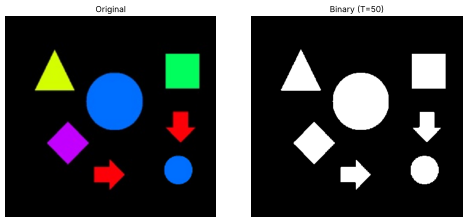

In [2]:
# Load the image and build a binary mask of the objects
img = load_image("objects.bmp")
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
_, binary = cv2.threshold(gray, 50, 255, cv2.THRESH_BINARY)
show([img, binary], ["Original", "Binary (T=50)"], size=(10, 4.5))

#### **01. 4-Connectivity vs. 8-Connectivity**

* **4-connectivity:** pixels are neighbors only through their edges (up, down, left, right).
* **8-connectivity:** diagonal neighbors also connect. Thin diagonal shapes can split into pieces with 4-connectivity.

In [3]:
# Label the objects with both connectivities (label 0 is the background)
for connectivity in (4, 8):
    count = cv2.connectedComponentsWithStats(binary, connectivity=connectivity)[0] - 1
    print(f"{connectivity}-connectivity: {count} objects")
count, labels, stats, centroids = cv2.connectedComponentsWithStats(binary, connectivity=8)

4-connectivity: 7 objects
8-connectivity: 7 objects


#### **02. Statistics per Object**

Each row of `stats` holds `LEFT`, `TOP`, `WIDTH`, `HEIGHT`, and `AREA`; `centroids` holds the center of mass.

id  left   top  width height   area       centroid
 1    56    63     76     78   3064      (94, 114)
 2   304    71     64     66   4224     (336, 104)
 3   154   107    106    108   9149     (207, 161)
 4   306   181     53     57   1615     (332, 207)
 5    80   200     78     80   3217     (119, 239)
 6   302   264     53     54   2275     (328, 291)
 7   169   272     57     56   1673     (195, 299)


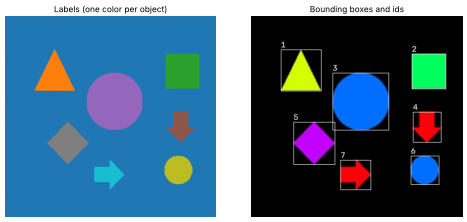

In [4]:
# Table of objects and annotated image
print(f"{'id':>2} {'left':>5} {'top':>5} {'width':>6} {'height':>6} {'area':>6} {'centroid':>14}")
annotated = img.copy()
for i in range(1, count):
    x, y, w, h, area = stats[i]
    cx, cy = centroids[i]
    print(f"{i:>2} {x:>5} {y:>5} {w:>6} {h:>6} {area:>6} {f'({cx:.0f}, {cy:.0f})':>14}")
    cv2.rectangle(annotated, (x, y), (x + w, y + h), (255, 255, 255), 1)
    cv2.putText(annotated, str(i), (x, y - 4), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 1)

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
axes[0].imshow(labels, cmap="tab10"); axes[0].set_title("Labels (one color per object)")
axes[1].imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB)); axes[1].set_title("Bounding boxes and ids")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

#### **Key Takeaways**

* Subtract 1 from the label count: label 0 is the background.
* Area, bounding box, and centroid are often enough to filter noise and classify simple objects.